# Lab 3.5 · Model file formats

**15–20 minutes · CPU**

Follow the [lab guide](README.md) for setup. Run the setup cell, make a prediction for each exercise, replace each `return None`, and run its check.

A weights file stores tensors under names. A runtime still needs the architecture that interprets those names. Safetensors uses a metadata header and raw tensor data so a reader can inspect shapes and load selected tensors. ONNX can describe the computation graph as well as its initializers, which may also be stored externally for large models.

Generate a linear layer, save it as safetensors, and reconstruct it from the named tensors. The layer definition is already supplied. The practical check is whether the loaded parameters fit that definition and reproduce the reference output.

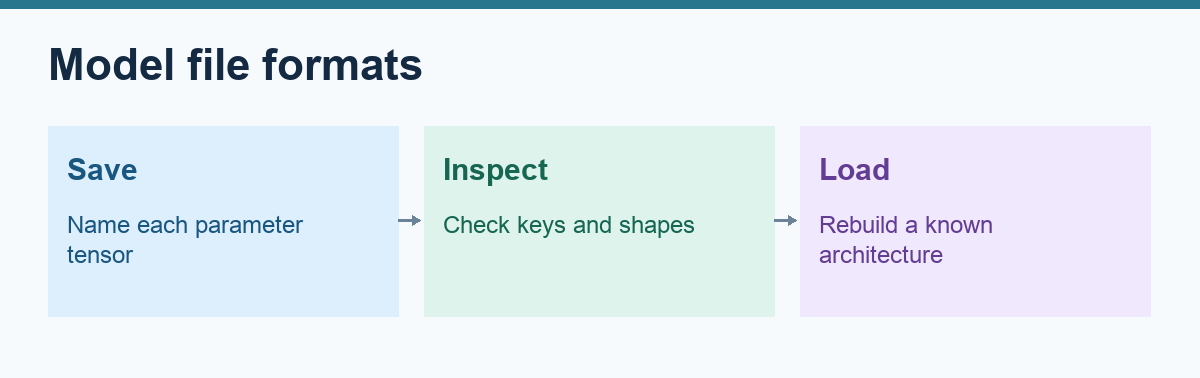

## Exercise map

| Exercise | What you will do | What to look for |
| --- | --- | --- |
| 1. Inspect a weights file | Inside safe_open with framework='pt' and device='cpu', use its keys and each get_slice(key).get_shape() to return a dictionary of shape tuples. | PyTorch stores linear weights as output-by-input. The layer applies the corresponding transpose internally. |
| 2. Rebuild and compare | Load the file into a fresh nn.Linear(4, 3), using a strict state-dict load. Return the model in eval mode. | The matching output depends on the architecture as well as on the stored bytes. |

In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
import torch
from torch import nn
from safetensors import safe_open
from safetensors.torch import load_file, save_file

torch.manual_seed(9)
model = nn.Linear(4, 3).eval()
x = torch.arange(8, dtype=torch.float32).reshape(2, 4)

## Exercise 1. Inspect a weights file

Inside safe_open with framework='pt' and device='cpu', use its keys and each get_slice(key).get_shape() to return a dictionary of shape tuples.

In [ ]:
def inspect_tensors(path):
    return None

In [ ]:
with TemporaryDirectory() as directory:
    path = Path(directory) / "weights.safetensors"
    save_file(model.state_dict(), str(path))
    shapes = inspect_tensors(path)
    if shapes is not None:
        assert shapes == {"weight": (3, 4), "bias": (3,)}
        print("PASS — stored tensor shapes:", shapes)

### Read the result

PyTorch stores linear weights as output-by-input. The layer applies the corresponding transpose internally.

## Exercise 2. Rebuild and compare

Load the file into a fresh nn.Linear(4, 3), using a strict state-dict load. Return the model in eval mode.

In [ ]:
def restore_layer(path):
    return None

In [ ]:
with TemporaryDirectory() as directory:
    path = Path(directory) / "weights.safetensors"
    save_file(model.state_dict(), str(path))
    restored = restore_layer(path)
    if restored is not None:
        with torch.inference_mode():
            torch.testing.assert_close(restored(x), model(x))
        assert not restored.training
        print("PASS — restored layer matches the reference")

### Read the result

The matching output depends on the architecture as well as on the stored bytes.

## Optional extension

Change the output width of the target layer and inspect the error from the strict load. Identify what model configuration would prevent that mismatch.

## Reading

Philip Kiely, *Inference Engineering*, §4.2.2, pp. 103–104.

- [Safetensors PyTorch API](https://huggingface.co/docs/safetensors/api/torch)